# Chapitre 1 - Cours 4 : la pile de l'AI engineering

Ce dernier notebook de cours accompagne la section *The AI Engineering Stack* du
chapitre 1 : les trois couches de toute application d'IA (*Three Layers of the AI
Stack*), ce qui distingue l'AI engineering du ML engineering classique (*AI Engineering
Versus ML Engineering*, avec ses sous-parties *Model development* et *Application
development*) et son rapprochement avec le développement full-stack (*AI Engineering
Versus Full-Stack Engineering*).

Plan :

1. les trois couches de la pile ;
2. ce qui ne change pas : métriques et expérimentation systématique (une vraie grille
   d'expériences sur des prompts) ;
3. AI engineering contre ML engineering : adapter plutôt qu'entraîner, des modèles plus
   gros, des sorties ouvertes ;
4. la couche développement de modèle (entraînement, données, optimisation de l'inférence) ;
5. la couche développement d'application (évaluation, prompt, interface) ;
6. AI engineering contre développement full-stack : le flux de travail inversé.

In [1]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch01_introduction as c1

c1.setup_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 120)

## 1. Les trois couches de la pile (section *Three Layers of the AI Stack*)

Face à l'avalanche quotidienne d'outils, de techniques et de modèles, le livre propose de
revenir aux briques fondamentales. Toute application d'IA repose sur trois couches :

- **développement d'application** : fournir au modèle de bons prompts et le contexte
  nécessaire, évaluer rigoureusement, construire une bonne interface. C'est la couche qui
  a connu le plus d'activité depuis l'arrivée des modèles de fondation ;
- **développement de modèle** : outils pour modéliser, entraîner, finetuner, optimiser
  l'inférence, et l'ingénierie des jeux de données ; l'évaluation y est aussi centrale ;
- **infrastructure** : servir les modèles, gérer données et calcul, surveiller.

On commence en général par la couche du haut, et on ne descend que si nécessaire.

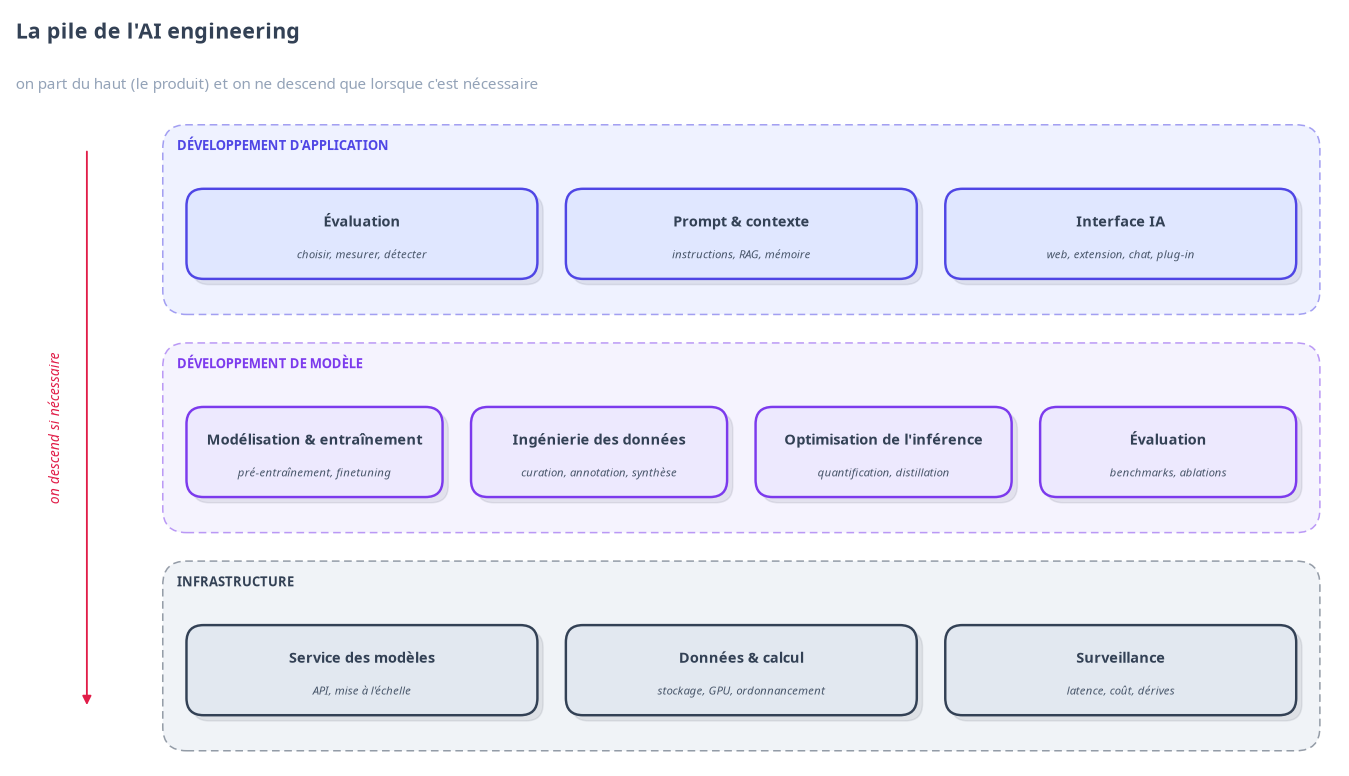

In [2]:
d = Diagram(14, 7.0, title="La pile de l'AI engineering",
            subtitle="on part du haut (le produit) et on ne descend que lorsque c'est nécessaire")
layers = [
    ("Développement d'application", INDIGO, 5.75,
     [("Évaluation", "choisir, mesurer, détecter"), ("Prompt & contexte", "instructions, RAG, mémoire"),
      ("Interface IA", "web, extension, chat, plug-in")]),
    ("Développement de modèle", VIOLET, 3.45,
     [("Modélisation & entraînement", "pré-entraînement, finetuning"), ("Ingénierie des données", "curation, annotation, synthèse"),
      ("Optimisation de l'inférence", "quantification, distillation"), ("Évaluation", "benchmarks, ablations")]),
    ("Infrastructure", SLATE, 1.15,
     [("Service des modèles", "API, mise à l'échelle"), ("Données & calcul", "stockage, GPU, ordonnancement"),
      ("Surveillance", "latence, coût, dérives")]),
]
for name, col, yc, items in layers:
    d.group(1.6, yc - 1.0, 13.8, yc + 1.0, name, col, alpha=0.5)
    n = len(items)
    w = (11.7 - 0.3 * (n - 1)) / n           # marge intérieure de 0,25 de chaque côté
    for i, (t, sub) in enumerate(items):
        x = 1.85 + w / 2 + i * (w + 0.3)
        d.box(f"{name}{i}", x, yc - 0.15, t, sub=sub, color=col, w=w, h=0.95, fontsize=9.5)
d.line([(0.8, 6.5), (0.8, 0.6)], color=ROSE, style="solid")
d.note(0.45, 3.55, "on descend si nécessaire", color=ROSE, fontsize=9)
d.ax.texts[-1].set_rotation(90)
d.show()

Le livre observe, en recensant les dépôts GitHub d'IA les plus populaires, une explosion
des outils de **développement d'application** (et des applications elles-mêmes) en 2023,
après Stable Diffusion et ChatGPT, tandis que la couche **infrastructure** a beaucoup
moins bougé : les besoins fondamentaux (gérer des ressources, servir, surveiller) restent
les mêmes, quel que soit le modèle.

> **À retenir.** Trois couches : application (prompt, contexte, évaluation, interface),
> modèle (entraînement, données, inférence, évaluation), infrastructure (service, calcul,
> surveillance). L'AI engineering commence en haut de la pile.

## 2. Ce qui ne change pas : métriques et expérimentation systématique (section *Three Layers of the AI Stack*)

Malgré l'effervescence, beaucoup de principes du ML engineering restent valables : une
application d'entreprise doit résoudre un problème métier, donc il faut relier métriques
métier et métriques de ML ; il faut **expérimenter systématiquement** (on ne règle plus
des hyperparamètres d'entraînement, mais des modèles, des prompts, des algorithmes de
recherche, des paramètres d'échantillonnage) ; il faut des modèles plus rapides et moins
chers ; et une boucle de retour avec les données de production.

**Une vraie grille d'expériences.** Classons le sentiment de 16 avis courts rédigés pour
ce dépôt, avec Qwen2.5-0.5B, en croisant 3 formulations de prompt et 2 régimes
(zéro exemple, 3 exemples dans le prompt : *few-shot*).

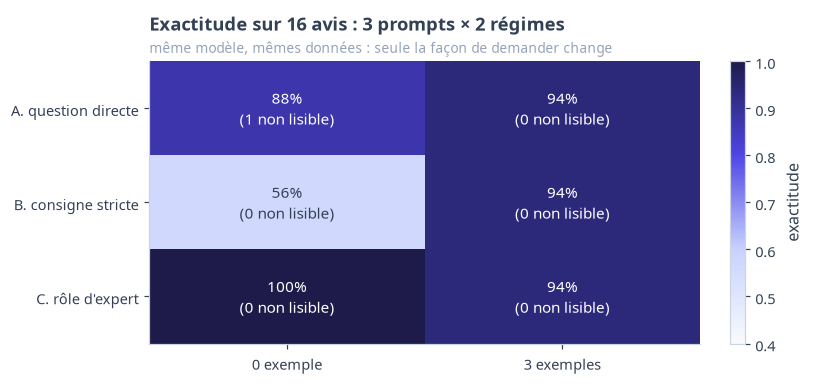

In [3]:
reviews = [
    ("Livraison en 24 h, produit conforme, je recommande.", "positif"),
    ("Le colis est arrivé ouvert et il manquait une pièce.", "négatif"),
    ("Très bon rapport qualité-prix, je rachèterai.", "positif"),
    ("Service client injoignable depuis deux semaines.", "négatif"),
    ("La batterie tient à peine une demi-journée.", "négatif"),
    ("Montage facile, notice claire, rien à redire.", "positif"),
    ("Taille trop petite, j'ai dû le renvoyer.", "négatif"),
    ("Superbe qualité, mes enfants l'adorent.", "positif"),
    ("Ça fait le travail, sans plus.", "négatif"),
    ("Remboursé rapidement après mon retour, merci.", "positif"),
    ("Odeur chimique très forte à l'ouverture.", "négatif"),
    ("Exactement comme sur les photos.", "positif"),
    ("Il est tombé en panne après trois jours.", "négatif"),
    ("Emballage soigné et petit mot manuscrit, adorable.", "positif"),
    ("Trop cher pour ce que c'est.", "négatif"),
    ("Le meilleur achat de l'année !", "positif"),
]
shots = [("Article reçu cassé, très déçu.", "négatif"), ("Parfait, rien à redire.", "positif"),
         ("Couleur différente de la photo, dommage.", "négatif")]
templates = {
    "A. question directe": "Cet avis est-il positif ou négatif ?\nAvis : {r}\nRéponse :",
    "B. consigne stricte": "Classe le sentiment de l'avis. Réponds uniquement par « positif » ou « négatif ».\nAvis : {r}",
    "C. rôle d'expert": "Tu es un analyste du service client. Indique si le client est satisfait (positif) ou insatisfait (négatif).\nAvis : {r}\nRéponds par un seul mot.",
}

def build_messages(tpl, r, k):
    msgs = []
    for sr, sl in shots[:k]:
        msgs += [{"role": "user", "content": tpl.format(r=sr)}, {"role": "assistant", "content": sl}]
    return msgs + [{"role": "user", "content": tpl.format(r=r)}]

def parse(ans):
    """Extrait l'étiquette d'une réponse libre ; « ? » si la réponse est inexploitable."""
    a = ans.lower()
    neg = any(w in a for w in ["négat", "negat", "insatisf"])
    pos = any(w in a for w in ["posit", "satisf"]) and not neg
    return "négatif" if neg else ("positif" if pos else "?")

acc = pd.DataFrame(index=list(templates), columns=["0 exemple", "3 exemples"], dtype=float)
unparsed = pd.DataFrame(0, index=list(templates), columns=acc.columns)
for name, tpl in templates.items():
    for k, col in [(0, "0 exemple"), (3, "3 exemples")]:
        preds = [parse(llm.chat(build_messages(tpl, r, k), llm.SMALL, max_new_tokens=24)) for r, _ in reviews]
        acc.loc[name, col] = np.mean([p == y for p, (_, y) in zip(preds, reviews)])
        unparsed.loc[name, col] = sum(p == "?" for p in preds)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
im = ax.imshow(acc.values.astype(float), cmap="aie_seq", vmin=0.4, vmax=1.0, aspect="auto")
ax.set_xticks(range(2), acc.columns); ax.set_yticks(range(3), acc.index); ax.grid(False)
for i in range(3):
    for j in range(2):
        v = acc.values[i, j]
        ax.text(j, i, f"{v:.0%}\n({unparsed.values[i, j]} non lisible)", ha="center", va="center",
                color="white" if v > 0.75 else SLATE, fontsize=10)
plt.colorbar(im, ax=ax, fraction=0.04, label="exactitude")
c1.title_sub(ax, "Exactitude sur 16 avis : 3 prompts × 2 régimes",
             "même modèle, mêmes données : seule la façon de demander change")
plt.tight_layout(); plt.show()

Sur un si petit jeu (16 avis), un écart de 6 points correspond à **un seul** avis : il faut
rester prudent dans les conclusions (le chapitre 4 traite de la taille des jeux
d'évaluation). Mais l'enseignement général tient. Sans exemple, la seule formulation fait
varier l'exactitude dans de grandes proportions, et la consigne qui paraît la plus
« propre » n'est pas forcément la meilleure : l'intuition ne remplace pas la mesure. Avec
trois exemples, les trois formulations convergent : les exemples montrent au modèle la
forme de réponse attendue et rendent le résultat bien moins sensible au libellé. Le cas
« Ça fait le travail, sans plus », que nous avons étiqueté négatif, est discutable : les
erreurs restantes révèlent aussi les ambiguïtés de nos propres étiquettes. D'où la règle
d'or : **comparer des modèles ou des versions dans des conditions de prompt identiques**,
et garder la trace de chaque configuration testée.

> **À retenir.** Les principes du ML engineering demeurent : relier métriques métier et
> métriques techniques, expérimenter systématiquement (désormais sur les prompts, les
> modèles, la recherche de contexte), optimiser coût et latence, boucler avec la production.

## 3. AI engineering contre ML engineering : trois différences (section *AI Engineering Versus ML Engineering*)

Le livre résume la différence en trois points :

1. **on adapte au lieu d'entraîner** : le modèle a été entraîné par quelqu'un d'autre ;
   l'effort porte sur l'adaptation, par le prompt (poids inchangés) ou par le finetuning
   (poids modifiés) ;
2. **les modèles sont plus gros**, consomment plus de calcul et ont une latence plus
   élevée : l'optimisation de l'entraînement et de l'inférence devient cruciale, et il
   faut savoir travailler avec des GPU et des grappes de calcul ;
3. **les sorties sont ouvertes** : plus de tâches possibles, mais une évaluation bien plus
   difficile.

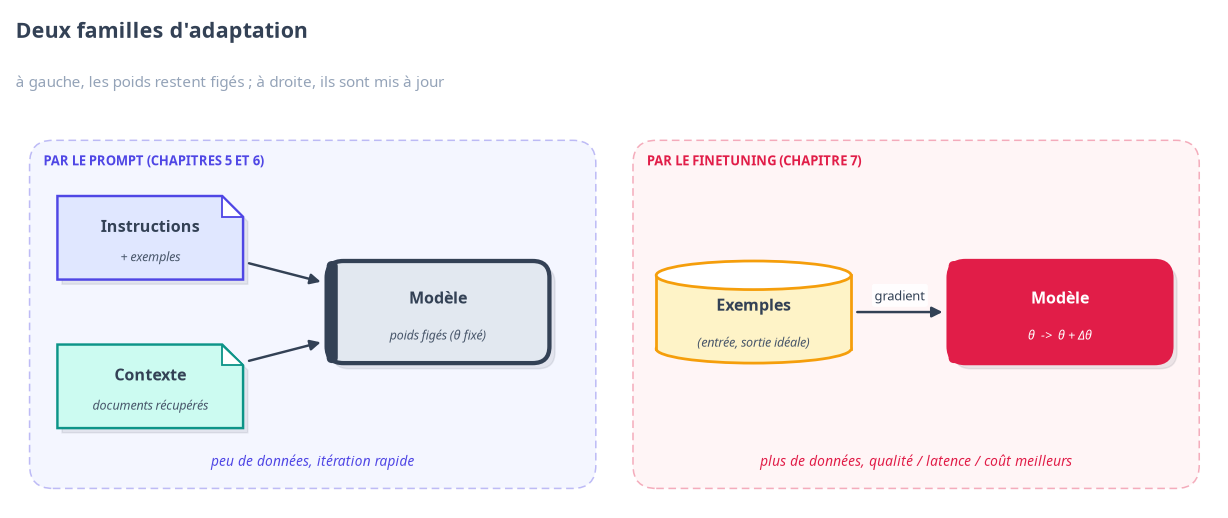

In [4]:
d = Diagram(13, 4.4, title="Deux familles d'adaptation", subtitle="à gauche, les poids restent figés ; à droite, ils sont mis à jour")
d.group(0.2, 0.2, 6.3, 3.95, "Par le prompt (chapitres 5 et 6)", INDIGO)
d.box("p_in", 1.5, 2.9, "Instructions", sub="+ exemples", color=INDIGO, kind="doc", w=2.0, h=0.9)
d.box("p_ctx", 1.5, 1.3, "Contexte", sub="documents récupérés", color=TEAL, kind="doc", w=2.0, h=0.9)
d.box("p_m", 4.6, 2.1, "Modèle", sub="poids figés (θ fixé)", color=SLATE, kind="model", w=2.4, h=1.1)
d.arrow("p_in", "p_m"); d.arrow("p_ctx", "p_m")
d.note(3.25, 0.5, "peu de données, itération rapide", color=INDIGO, fontsize=9)
d.group(6.7, 0.2, 12.8, 3.95, "Par le finetuning (chapitre 7)", ROSE)
d.box("f_d", 8.0, 2.1, "Exemples", sub="(entrée, sortie idéale)", color=AMBER, kind="db", w=2.1, h=1.1)
d.box("f_m", 11.3, 2.1, "Modèle", sub="θ  ->  θ + Δθ", color=ROSE, kind="model", w=2.4, h=1.1, filled=True)
d.arrow("f_d", "f_m", "gradient")
d.note(9.75, 0.5, "plus de données, qualité / latence / coût meilleurs", color=ROSE, fontsize=9)
d.show()

**Des modèles plus gros.** Mettons en regard des modèles « classiques » et des modèles de
fondation, en nombre de paramètres (ordres de grandeur typiques).

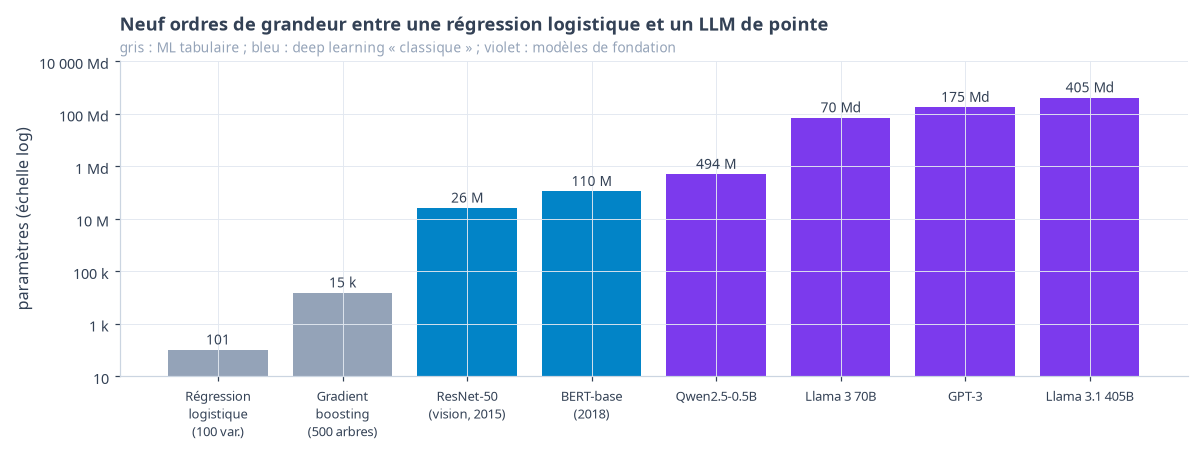

In [5]:
sizes = {"Régression\nlogistique\n(100 var.)": 101, "Gradient\nboosting\n(500 arbres)": 1.5e4,
         "ResNet-50\n(vision, 2015)": 25.6e6, "BERT-base\n(2018)": 110e6, "Qwen2.5-0.5B": 494e6,
         "Llama 3 70B": 70e9, "GPT-3": 175e9, "Llama 3.1 405B": 405e9}
fig, ax = plt.subplots(figsize=(11, 4.2))
cols = [GRAY, GRAY, SKY, SKY, VIOLET, VIOLET, VIOLET, VIOLET]
ax.bar(list(sizes), list(sizes.values()), color=cols)
ax.set_yscale("log"); c1.human_log(ax)
for i, v in enumerate(sizes.values()):
    ax.text(i, v * 1.6, c1.human_number(v), ha="center", fontsize=9)
ax.set_ylabel("paramètres (échelle log)")
ax.tick_params(axis="x", labelsize=8.5)
ax.set_ylim(10, 1e13)
c1.title_sub(ax, "Neuf ordres de grandeur entre une régression logistique et un LLM de pointe",
             "gris : ML tabulaire ; bleu : deep learning « classique » ; violet : modèles de fondation")
plt.tight_layout(); plt.show()

**Des sorties ouvertes.** Un classifieur de spam n'a que deux sorties possibles : on compare
à la vérité terrain et c'est fini. Demandez à un modèle génératif un nom de boulangerie,
et il existe une infinité de bonnes réponses. Échantillonnons 10 réponses (température
1,0, graines fixées) pour une même question.

In [6]:
q = "Propose un nom original pour une boulangerie de quartier. Réponds uniquement par le nom."
answers = [re.sub(r"[«»\"*.]", "", llm.chat(q, llm.SMALL, max_new_tokens=12, temperature=1.0, seed=s)).strip()
           for s in range(10)]
cnt = Counter(answers)
print(f"{len(cnt)} réponses distinctes sur {len(answers)} :")
for a_, n_ in cnt.most_common():
    print(f"  {n_} × {a_[:60]}")

10 réponses distinctes sur 10 :
  1 × Boulotte
  1 × Flora Boulangerie
  1 × Delice Delicata
  1 × La Boulangerie du Marché
  1 × Locum Bakery
  1 × Lampoonerie
  1 × Locale Boulangerie
  1 × Boulangeria
  1 × Epic Biscuit Shop
  1 × Cafe La Bocotte


Presque toutes les réponses sont différentes. Certaines sont bancales (un nom anglais, un
mot inventé peu heureux), plusieurs sont parfaitement acceptables : aucune liste de
« bonnes réponses » ne peut être exhaustive, et juger lesquelles sont « bonnes » demande
des critères explicites (originalité ? langue ? prononçabilité ?). On ne peut pas évaluer par simple égalité
avec une référence ; il faudra des critères, des juges (humains ou IA), des comparaisons
(chapitres 3 et 4). C'est pourquoi l'**évaluation** est le grand défi de l'AI engineering.

> **À retenir.** L'AI engineering, c'est moins de modélisation et plus d'**adaptation** et
> d'**évaluation** ; avec des modèles plus gros (calcul, latence) aux sorties ouvertes
> (évaluation difficile).

## 4. La couche développement de modèle (section *Model development*)

Trois responsabilités : **modélisation et entraînement**, **ingénierie des données**,
**optimisation de l'inférence** (plus l'évaluation, traitée en section 5).

**Modélisation et entraînement.** Concevoir une architecture, l'entraîner, la finetuner :
c'est le domaine de TensorFlow, PyTorch, Transformers. Les connaissances de ML (descente
de gradient, fonction de perte, régularisation...) ne sont plus **indispensables** pour
construire une application, mais restent précieuses pour élargir sa boîte à outils et
diagnostiquer un modèle qui se comporte mal. Le livre précise le vocabulaire :

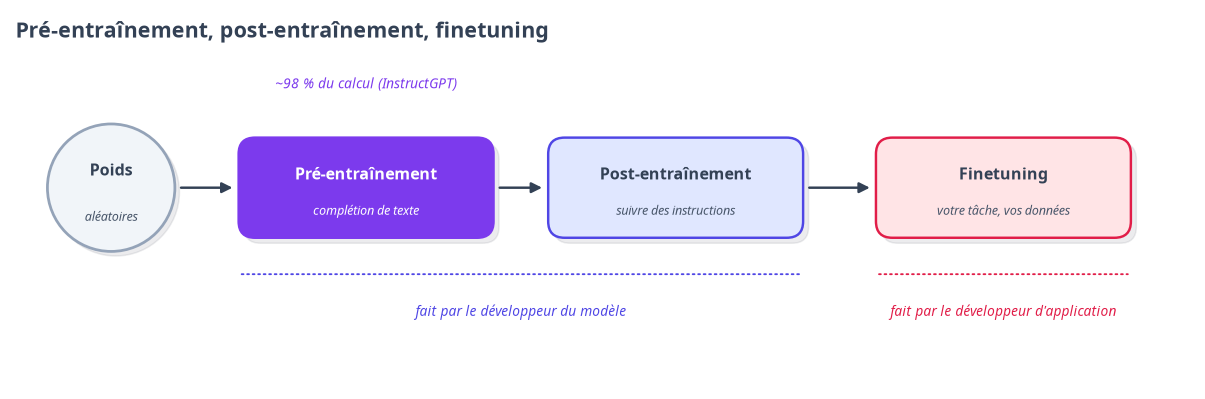

In [7]:
d = Diagram(13, 3.6, title="Pré-entraînement, post-entraînement, finetuning")
d.box("init", 1.1, 2.2, "Poids", sub="aléatoires", color=GRAY, kind="circle", w=1.4)
d.box("pre", 3.9, 2.2, "Pré-entraînement", sub="complétion de texte", color=VIOLET, w=2.8, h=1.1, filled=True)
d.box("post", 7.3, 2.2, "Post-entraînement", sub="suivre des instructions", color=INDIGO, w=2.8, h=1.1)
d.box("ft", 10.9, 2.2, "Finetuning", sub="votre tâche, vos données", color=ROSE, w=2.8, h=1.1)
d.arrow("init", "pre"); d.arrow("pre", "post"); d.arrow("post", "ft")
d.note(3.9, 3.35, "~98 % du calcul (InstructGPT)", color=VIOLET, fontsize=9)
d.note(5.6, 0.85, "fait par le développeur du modèle", color=INDIGO, fontsize=9)
d.note(10.9, 0.85, "fait par le développeur d'application", color=ROSE, fontsize=9)
d.line([(2.5, 1.25), (8.7, 1.25)], color=INDIGO, style="dotted", arrow=False)
d.line([(9.5, 1.25), (12.3, 1.25)], color=ROSE, style="dotted", arrow=False)
d.show()

Le **pré-entraînement** part de poids aléatoires et consomme l'essentiel des ressources ;
le **post-entraînement** et le **finetuning** poursuivent l'entraînement d'un modèle déjà
entraîné (les deux mots désignent la même opération ; on dit plutôt post-entraînement
quand c'est le développeur du modèle, finetuning quand c'est le développeur
d'application). Attention à deux abus de langage relevés par le livre : la quantification
modifie les poids **sans** être un entraînement ; et « entraîner ChatGPT » en lui donnant
des documents dans la conversation est en fait de l'**ingénierie de prompt** (les poids ne
changent pas).

**Ingénierie des données.** En ML classique, on annote surtout des tâches fermées (« spam »
ou non) sur des données tabulaires, et l'on fait de l'ingénierie de variables. Avec les
modèles de fondation, les données sont non structurées et les sorties ouvertes : écrire une
réponse idéale coûte bien plus cher que cocher une case, et le travail porte sur la
**déduplication**, la **tokenisation**, la récupération de contexte et le **contrôle
qualité** (données sensibles, toxiques). Petit exemple de déduplication sur un mini-jeu
d'instructions.

In [8]:
dataset = [
    "Résume ce texte en une phrase.", "Résume ce texte en une phrase !", "résume ce texte en une phrase",
    "Traduis cette phrase en anglais.", "Traduis   cette phrase en anglais.", "Écris un poème sur la mer.",
    "Donne trois idées de dîner végétarien.", "Explique la photosynthèse à un enfant de 8 ans.",
    "Explique la photosynthèse à un enfant de huit ans.", "Écris un poème sur la mer.",
]
norm = lambda t: re.sub(r"[^\w ]", "", re.sub(r"\s+", " ", t.lower())).strip()
exact = len(set(dataset)); normalized = len({norm(t) for t in dataset})
tok = c1.get_tokenizer("Qwen2.5")
pd.DataFrame({"étape": ["brut", "doublons exacts retirés", "après normalisation (casse, ponctuation, espaces)"],
              "exemples": [len(dataset), exact, normalized],
              "tokens (Qwen2.5)": [sum(tok.count(t) for t in dataset), sum(tok.count(t) for t in set(dataset)),
                                   sum(tok.count(t) for t in {norm(t): t for t in dataset}.values())]})

,étape,exemples,tokens (Qwen2.5)
0,brut,10,105
1,doublons exacts retirés,9,95
2,"après normalisation (casse, ponctuation, espaces)",6,72


La normalisation élimine des doublons que l'égalité stricte manque ; il reste des
**quasi-doublons** (« 8 ans » / « huit ans ») qui demandent des méthodes plus fines
(MinHash, embeddings : chapitre 8). Des doublons dans les données d'entraînement ou
d'évaluation faussent les deux.

**Optimisation de l'inférence.** Le livre souligne une difficulté propre aux modèles
autorégressifs : les tokens sont générés **séquentiellement**. À 10 ms par token, 100 tokens
prennent une seconde, loin des 100 ms attendues d'une application web. En revanche, les
tokens du **prompt** sont traités **en parallèle** (phase de *prefill*). Vérifions-le en
mesurant le TTFT pour des prompts de longueurs croissantes, et la latence totale pour des
sorties de longueurs croissantes.

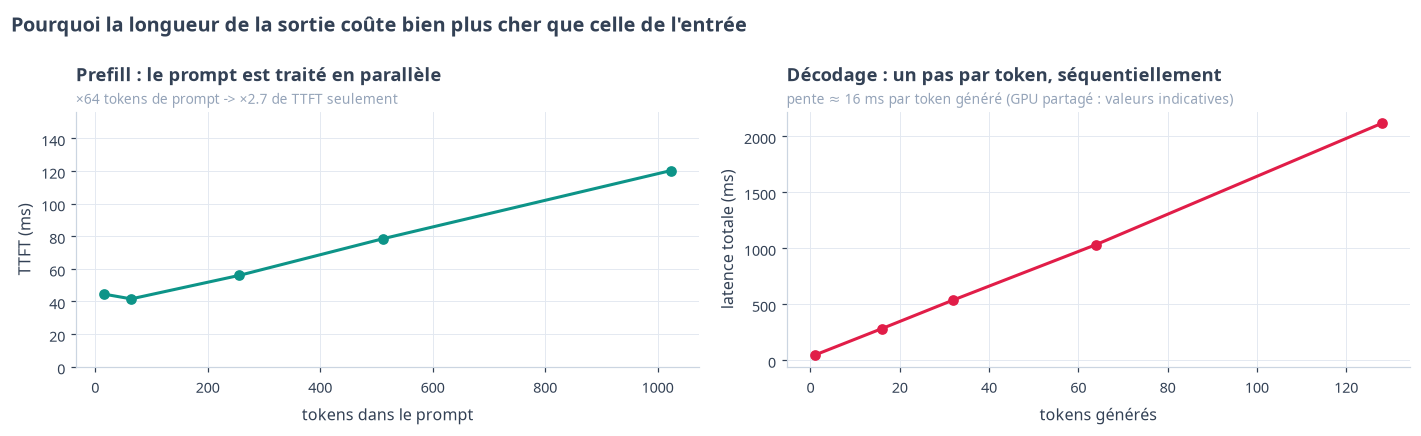

In [9]:
import time
import torch

tok_q, model_q = llm.load(llm.SMALL)

def timed(ids, n_new):
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        model_q.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=n_new, min_new_tokens=n_new,
                         do_sample=False, temperature=None, top_p=None, top_k=None, pad_token_id=tok_q.pad_token_id)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter() - t0

base_ids = tok_q(c1.CORPUS_FR * 3, return_tensors="pt")["input_ids"].to(model_q.device)
timed(base_ids[:, :32], 4)  # échauffement
prompt_lens = [16, 64, 256, 512, 1024]
ttft = [np.median([timed(base_ids[:, :L], 1) for _ in range(3)]) for L in prompt_lens]
out_lens = [1, 16, 32, 64, 128]
tot = [np.median([timed(base_ids[:, :64], n) for _ in range(2)]) for n in out_lens]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(prompt_lens, np.array(ttft) * 1000, "o-", color=TEAL)
axes[0].set_xlabel("tokens dans le prompt"); axes[0].set_ylabel("TTFT (ms)")
axes[0].set_ylim(0, max(max(ttft) * 1000 * 1.3, 1))
c1.title_sub(axes[0], "Prefill : le prompt est traité en parallèle",
             f"×{prompt_lens[-1] // prompt_lens[0]} tokens de prompt -> ×{ttft[-1] / ttft[0]:.1f} de TTFT seulement")
axes[1].plot(out_lens, np.array(tot) * 1000, "o-", color=ROSE)
axes[1].set_xlabel("tokens générés"); axes[1].set_ylabel("latence totale (ms)")
slope = np.polyfit(out_lens, np.array(tot) * 1000, 1)[0]
c1.title_sub(axes[1], "Décodage : un pas par token, séquentiellement",
             f"pente ≈ {slope:.0f} ms par token généré (GPU partagé : valeurs indicatives)")
finish(fig, "Pourquoi la longueur de la sortie coûte bien plus cher que celle de l'entrée"); plt.show()

Multiplier par 64 la longueur du prompt ne multiplie le TTFT que par quelques unités (le
GPU traite ces tokens en parallèle, tant qu'il n'est pas saturé) : traiter un millier de
tokens de prompt coûte à peu près autant que d'en **générer** une poignée, car chaque token
généré exige un pas complet du modèle. C'est aussi pourquoi les fournisseurs facturent souvent les tokens de sortie
plusieurs fois plus cher que ceux d'entrée. Quantification, distillation, parallélisme et
décodage spéculatif (chapitres 7 à 9) visent précisément ce goulot.

Le livre résume l'évolution de cette couche dans un tableau, reformulé ici :

In [10]:
pd.DataFrame({
    "ML classique": ["indispensable pour entraîner un modèle de zéro",
                     "surtout de l'ingénierie de variables, données tabulaires",
                     "importante"],
    "Modèles de fondation": ["utile mais non obligatoire (point débattu)",
                             "déduplication, tokenisation, récupération de contexte, contrôle qualité",
                             "encore plus importante"],
}, index=["Modélisation et entraînement", "Ingénierie des données", "Optimisation de l'inférence"])

,ML classique,Modèles de fondation
Modélisation et entraînement,indispensable pour entraîner un modèle de zéro,utile mais non obligatoire (point débattu)
Ingénierie des données,"surtout de l'ingénierie de variables, données tabulaires","déduplication, tokenisation, récupération de contexte, contrôle qualité"
Optimisation de l'inférence,importante,encore plus importante


> **À retenir.** Développement de modèle = entraînement (pré-, post-, finetuning), données
> (non structurées, sorties ouvertes, déduplication), inférence (prefill parallèle mais
> décodage séquentiel : la longueur de sortie domine la latence).

## 5. La couche développement d'application (section *Application development*)

En ML classique, la qualité du modèle propriétaire faisait la différence. Quand tout le
monde utilise les mêmes modèles, la différence se fait dans l'**application** : évaluation,
ingénierie de prompt et construction du contexte, interface.

**Évaluation.** Elle sert à choisir un modèle, mesurer les progrès, décider d'un
déploiement, détecter les problèmes en production. Elle est plus difficile qu'avant : sorties
ouvertes, et multiplicité des techniques d'adaptation. L'exemple du livre est frappant : au
lancement de Gemini (décembre 2023), Google annonce que Gemini Ultra bat GPT-4 sur le
benchmark MMLU... avec un prompt « CoT@32 » (32 échantillons avec raisonnement) contre 5
exemples pour GPT-4. À conditions égales (5 exemples), le classement s'inverse.

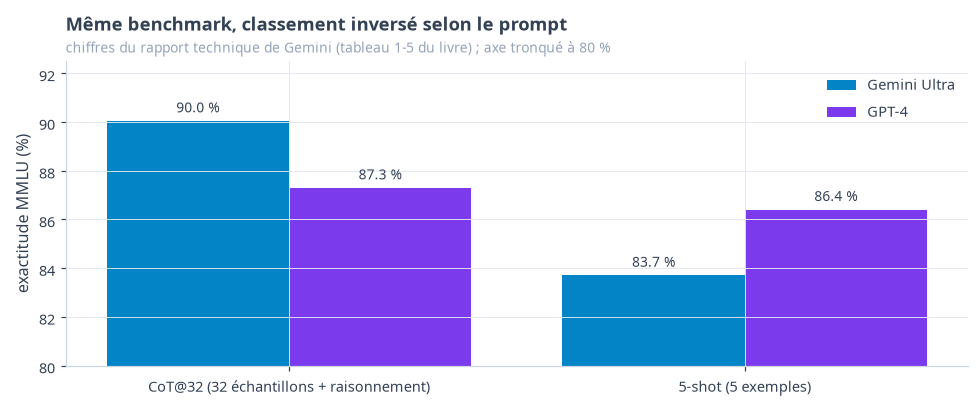

In [11]:
mmlu = pd.DataFrame({"Gemini Ultra": [90.04, 83.7], "GPT-4": [87.29, 86.4]},
                    index=["CoT@32 (32 échantillons + raisonnement)", "5-shot (5 exemples)"])
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(2)
ax.bar(x - 0.2, mmlu["Gemini Ultra"], 0.4, color=SKY, label="Gemini Ultra")
ax.bar(x + 0.2, mmlu["GPT-4"], 0.4, color=VIOLET, label="GPT-4")
annotate_bars(ax, "{:.1f} %")
ax.set_xticks(x, mmlu.index)
ax.set_ylim(80, 92.5); ax.set_ylabel("exactitude MMLU (%)")
ax.legend(loc="upper right")
c1.title_sub(ax, "Même benchmark, classement inversé selon le prompt",
             "chiffres du rapport technique de Gemini (tableau 1-5 du livre) ; axe tronqué à 80 %")
plt.tight_layout(); plt.show()

Le même modèle gagne plus de 6 points en changeant de technique de prompt : c'est aussi la
meilleure illustration de la puissance de l'**ingénierie de prompt**, qui consiste à obtenir
le comportement voulu à partir de l'entrée seule, sans changer les poids. Elle inclut le
fait de fournir le **contexte** et les **outils** nécessaires (chapitre 5 pour le prompt,
chapitre 6 pour le contexte et les agents).

**Interface.** Avant les modèles de fondation, l'IA était surtout embarquée dans les
produits des organisations capables de l'entraîner (détection de fraude chez Stripe,
recommandation chez Netflix). Aujourd'hui, n'importe qui peut proposer une application
autonome ou l'intégrer à des produits existants, y compris ceux des autres.

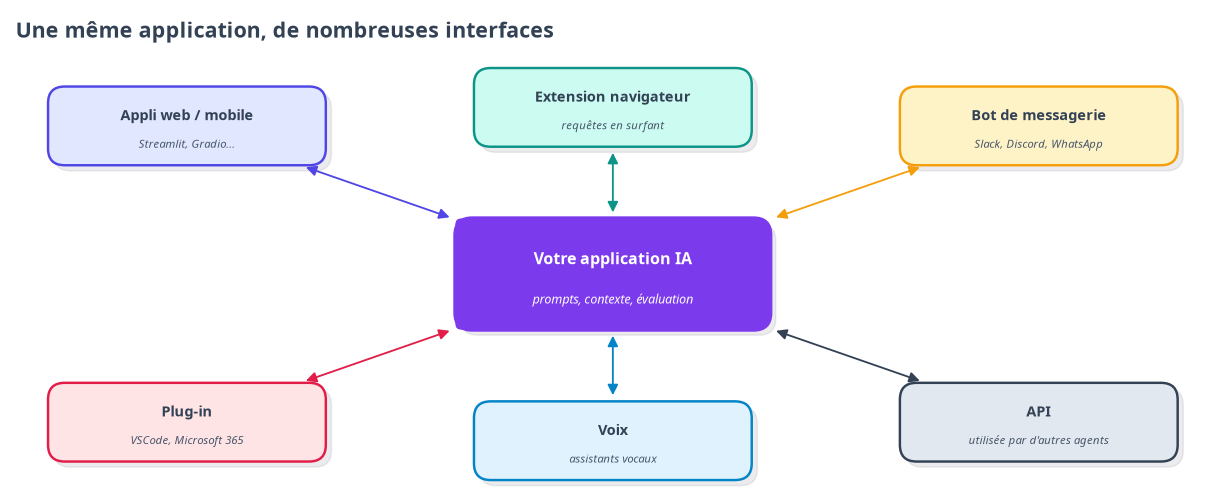

In [12]:
d = Diagram(13, 4.6, title="Une même application, de nombreuses interfaces")
d.box("core", 6.5, 2.3, "Votre application IA", sub="prompts, contexte, évaluation", color=VIOLET, kind="model", w=3.4, h=1.2, filled=True)
ifaces = [("Appli web / mobile", "Streamlit, Gradio...", 1.9, 3.9, INDIGO), ("Extension navigateur", "requêtes en surfant", 6.5, 4.1, TEAL),
          ("Bot de messagerie", "Slack, Discord, WhatsApp", 11.1, 3.9, AMBER), ("Plug-in", "VSCode, Microsoft 365", 1.9, 0.7, ROSE),
          ("Voix", "assistants vocaux", 6.5, 0.5, SKY), ("API", "utilisée par d'autres agents", 11.1, 0.7, SLATE)]
for i, (t, sub, x, y, col) in enumerate(ifaces):
    d.box(f"i{i}", x, y, t, sub=sub, color=col, w=3.0, h=0.85, fontsize=9.5)
    d.arrow("core", f"i{i}", color=col, both=True, lw=1.2)
d.show()

In [13]:
pd.DataFrame({"ML classique": ["moins importante", "sans objet", "importante"],
              "Modèles de fondation": ["importante", "importante", "encore plus importante"]},
             index=["Interface IA", "Ingénierie de prompt", "Évaluation"])

,ML classique,Modèles de fondation
Interface IA,moins importante,importante
Ingénierie de prompt,sans objet,importante
Évaluation,importante,encore plus importante


Les nouvelles interfaces (conversationnelles surtout) facilitent aussi le **retour
utilisateur** en langage naturel, plus riche mais plus difficile à exploiter (chapitre 10).

> **À retenir.** Quand le modèle est partagé, la différence se fait dans l'application :
> une évaluation rigoureuse (attention aux comparaisons à prompts différents), un bon
> prompt avec le bon contexte, et une interface adaptée aux usages.

## 6. AI engineering contre développement full-stack (section *AI Engineering Versus Full-Stack Engineering*)

L'importance croissante de l'interface rapproche l'AI engineering du développement
full-stack. Les outils suivent : longtemps centré sur Python, l'écosystème propose
désormais des API JavaScript (LangChain.js, Transformers.js, la bibliothèque Node d'OpenAI,
l'AI SDK de Vercel), et de plus en plus d'AI engineers viennent du développement web. Leur
atout : transformer très vite une idée en démo, recueillir des retours, itérer.

Surtout, **le flux de travail s'inverse**. En ML classique, on collecte des données, on
entraîne un modèle, et le produit vient en dernier. Avec des modèles disponibles sur
étagère, on peut commencer par le produit et n'investir dans les données et les modèles que
si le produit montre du potentiel (le livre reprend un schéma de Shawn Wang, *The Rise of
the AI Engineer*, 2023).

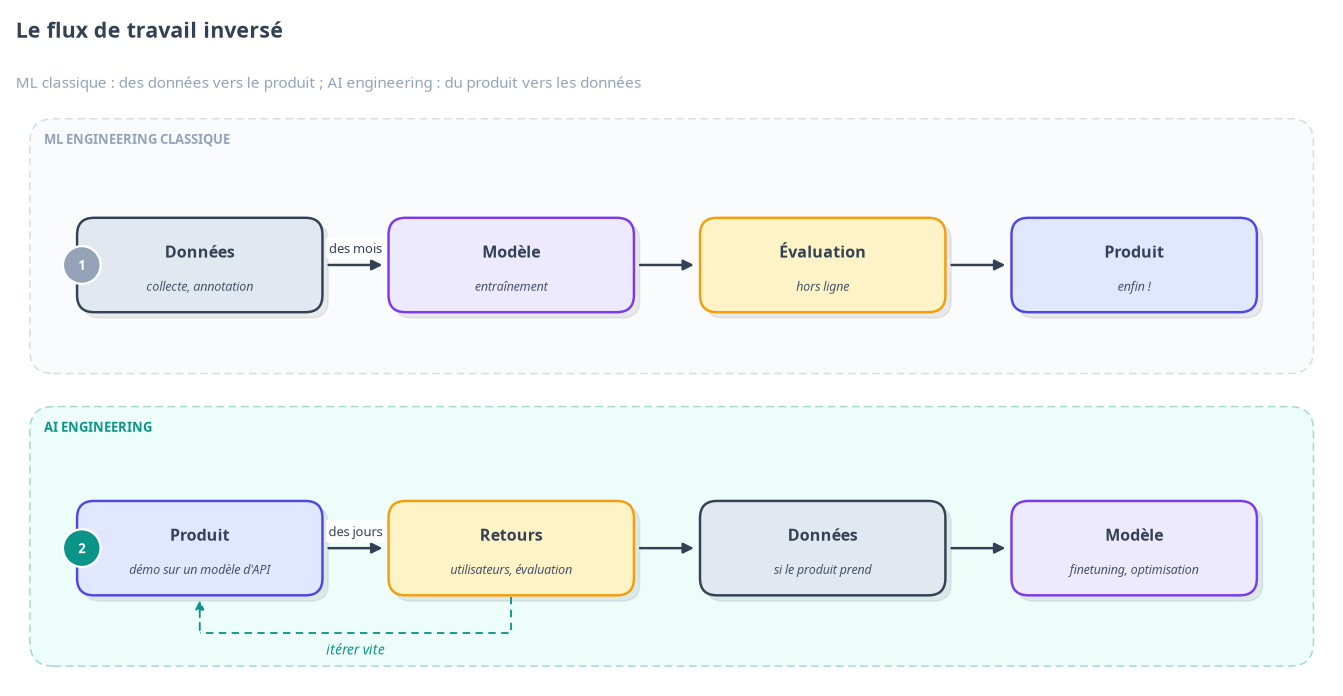

In [14]:
d = Diagram(14, 6.2, title="Le flux de travail inversé",
            subtitle="ML classique : des données vers le produit ; AI engineering : du produit vers les données")
d.group(0.2, 3.3, 13.8, 6.0, "ML engineering classique", GRAY)
ml = [("ml1", "Données", "collecte, annotation"), ("ml2", "Modèle", "entraînement"),
      ("ml3", "Évaluation", "hors ligne"), ("ml4", "Produit", "enfin !")]
d.flow(ml, y=4.45, x0=2.0, dx=3.3, w=2.6, h=1.0, colors=[SLATE, VIOLET, AMBER, INDIGO],
       labels=["des mois", "", ""])
d.badge(0.75, 4.45, "1", color=GRAY)
d.group(0.2, 0.2, 13.8, 2.95, "AI engineering", TEAL)
ae = [("ae1", "Produit", "démo sur un modèle d'API"), ("ae2", "Retours", "utilisateurs, évaluation"),
      ("ae3", "Données", "si le produit prend"), ("ae4", "Modèle", "finetuning, optimisation")]
d.flow(ae, y=1.45, x0=2.0, dx=3.3, w=2.6, h=1.0, colors=[INDIGO, AMBER, SLATE, VIOLET],
       labels=["des jours", "", ""])
d.badge(0.75, 1.45, "2", color=TEAL)
d.line([(5.3, 0.93), (5.3, 0.55), (2.0, 0.55), (2.0, 0.93)], color=TEAL, style="dashed")
d.note(3.65, 0.38, "itérer vite", color=TEAL, fontsize=9)
d.show()

En ML classique, les ingénieurs ML participent rarement aux décisions produit ; en AI
engineering, ils sont au cœur de la construction du produit. Un interlocuteur de l'auteur
résume : l'AI engineering, c'est de l'ingénierie logicielle avec des modèles d'IA dans la
pile.

> **À retenir.** L'AI engineering se rapproche du full-stack : interfaces, JavaScript,
> itération rapide. Le flux s'inverse : produit d'abord, données et modèles ensuite, quand
> la valeur est démontrée.

## Synthèse

- Toute application d'IA repose sur **trois couches** : application, modèle,
  infrastructure. On commence en haut.
- Les **principes** du ML engineering restent valables (métriques, expérimentation
  systématique, coût, boucle de retour), mais on expérimente désormais sur les prompts et
  les modèles : notre grille de 6 configurations l'a montré.
- Trois **différences** : adapter plutôt qu'entraîner (prompt ou finetuning), des modèles
  9 ordres de grandeur plus gros qu'une régression logistique (calcul, latence, GPU), des
  sorties ouvertes (évaluation difficile).
- **Développement de modèle** : pré-entraînement / post-entraînement / finetuning,
  ingénierie des données non structurées, optimisation de l'inférence (le décodage
  séquentiel domine la latence).
- **Développement d'application** : évaluation (attention aux comparaisons biaisées par le
  prompt), ingénierie de prompt et de contexte, interfaces multiples.
- **Full-stack** : le flux s'inverse, produit d'abord.

**Liens.** Ce cours sert de carte pour tout le livre : chapitres 2 (modèles de fondation),
3-4 (évaluation), 5 (prompt), 6 (RAG et agents), 7 (finetuning), 8 (données), 9
(inférence), 10 (architecture et retours utilisateurs).

In [15]:
llm.free_gpu()